## NBA rookies: will a player stay in the league for more than 5 years?
### Data exploration and model selection
The dataset is not included in this repository for confidentiality reasons.
- **Target:** 'TARGET_5Yrs' (1 = the player lasted at least 5 years).
- **Goal:** find as many future long-career players as possible.
- **Method:** the exploration sections use a scaled copy of the data for plots only.

In [ ]:
import pickle  # model saving
from pathlib import Path

# data visualization
from matplotlib import pyplot as plt
import seaborn as sns

# data processing
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.decomposition import PCA  # data reduction
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer

# model selection
from sklearn.metrics import (
    confusion_matrix,
    recall_score,
    accuracy_score,
    precision_score,
    precision_recall_curve
)
from sklearn.model_selection import (
    StratifiedKFold,
    train_test_split,
    GridSearchCV,
    RepeatedStratifiedKFold,
    cross_val_predict
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler  # data normalisation

# classifiers
from sklearn.svm import SVC  # support vector classifier
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")

RANDOM_STATE = 50
TARGET = "TARGET_5Yrs"
DATA_PATH = Path("data") / "nba_logreg.csv"  # Confidential

## 1. Load dataset

In [2]:
df = pd.read_csv(".\\nba_logreg.csv")

In [ ]:
df.describe()

In [ ]:
df.info()  # to check if there are missing values in the dataset and to check the types of the columns

In [5]:
# Separate the labels from the numeric features
labels = df[TARGET].to_numpy()
X_raw = df.drop(columns=[TARGET, "Name"])
feature_names = X_raw.columns.to_list()

### Class balance
Checking the balance confirms that recall is the right metric to optimise. Missing a future long-career player will cost more than a false alarm.

In [6]:
df[TARGET].value_counts(normalize=True)

1.0    0.620149
0.0    0.379851
Name: TARGET_5Yrs, dtype: float64

### Missing values
Missing values only appear for players who never attempted a three-point shot, so fillinf them with 0 is reasonable.

In [7]:
missing = X_raw.isna().sum()
missing[missing > 0]

3P%    11
dtype: int64

In [8]:
# Scaled copy for exploration and plots
X_expl = pd.DataFrame(
    MinMaxScaler().fit_transform(X_raw.fillna(0)),
    columns=feature_names
)

## 2. Exploration

In [ ]:
# Outliers
plt.figure(figsize=(8, 8))
sns.boxplot(data=X_expl, orient="h")
plt.show()

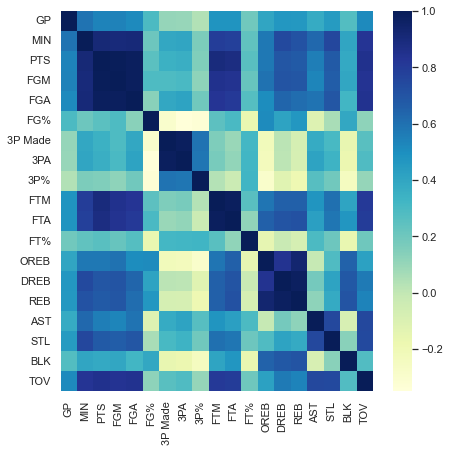

In [ ]:
# Correlations between features
plt.figure(figsize=(7, 7))
sns.heatmap(X_raw.corr(), cmap='YlGnBu')
plt.show()

A decorrelation can be a good idea to choose the features.

In [ ]:
# Feature distributions
X_raw.hist(bins=20, figsize=(20,10), color='lightblue', edgecolor = 'red')
plt.tight_layout()
plt.show()

These histograms show that the features should be normalised before modelling.

In [ ]:
# Comparison of the two classes
sns.pairplot(df.drop(columns=['Name']), hue=TARGET);

It is noticeable that players with more than five years in the NBA generally have higher sports statistics than others, which is logical.

In [ ]:
df.groupby(TARGET).mean(numeric_only=True)  # to see the serious differences between the two classes

In [ ]:
# Class means after scaling, to compare features on the same footing
X_expl.groupby(labels).mean().T.plot(kind="bar", figsize=(17, 8))
plt.show()

**Observations:** The biggest difference between the two categories is the number of games played, which is noticeably higher for wanted players. We see that the time played is also important. The statistics on the three points are similar in both categories.

## 3. Feature reduction (exploratory)
### 3.1 Decorrelation

In [15]:
def get_high_correlation_pairs(features, threshold=0.5):
    """Return feature pairs whose absolute Pearson correlation exceeds a threshold.
    Each pair appears once, sorted from most to least correlated."""
    corr = features.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    pairs = upper.stack()
    return pairs[pairs > threshold].sort_values(ascending=False)

def columns_to_drop(pairs, variances):
    """For every correlated pair, mark the feature with the lower variance."""
    to_drop = set()
    for col_a, col_b in pairs.index:
        to_drop.add(col_b if variances[col_a] > variances[col_b] else col_a)
    return sorted(to_drop)

X_expl.var().describe()

count    19.000000
mean      0.025792
std       0.012006
min       0.011190
25%       0.018043
50%       0.025108
75%       0.028032
max       0.060294
dtype: float64

In [16]:
high_corr = get_high_correlation_pairs(X_expl, threshold=0.5)
dropped = columns_to_drop(high_corr, X_expl.var())
X_decorrelated = X_expl.drop(columns=dropped)
print(f"{len(high_corr)} pairs above 0.5, dropped: {dropped}")
print(f"Remaining features: {X_decorrelated.columns.to_list()}")

69 pairs above 0.5, dropped: ['3P%', '3PA', 'AST', 'BLK', 'DREB', 'FG%', 'FGA', 'FGM', 'FTA', 'FTM', 'MIN', 'OREB', 'PTS', 'REB', 'STL', 'TOV']
Remaining features: ['GP', '3P Made', 'FT%']


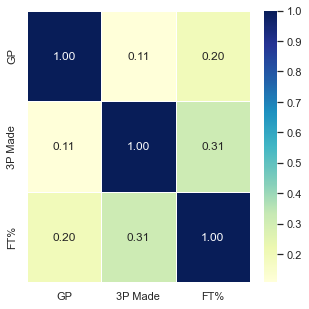

In [17]:
plt.figure(figsize=(5, 5))
sns.heatmap(X_decorrelated.corr(), cmap='YlGnBu', annot=True, fmt=".2f", linewidths=.5)  # plot the correlation matrix
plt.show()

There are only few features left, which is not ideal. The number of games played is still there, though some features that don't have as much impact have also been kept (3P Made). This is normal since the decorrelation summarises the dataset and does not look for the most informative features.

### 3.2 PCA
PCA is generally used for dimensionality reduction, but can also be used for visualization.

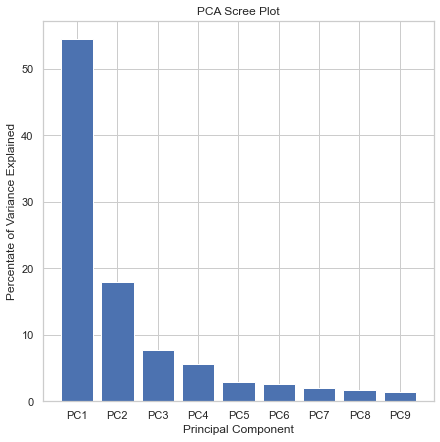

In [18]:
pca = PCA(n_components=0.95)  # keep 95% of the variance
x_pca = pca.fit_transform(X_expl)
n_components = pca.n_components_
percent_variance = np.round(pca.explained_variance_ratio_ * 100, 2)  # get the percentage of variance explained by each component

plt.figure(figsize=(7, 7))
plt.bar(
    range(1, n_components + 1),
    percent_variance,
    tick_label=[f"PC{i}" for i in range(1, n_components + 1)]
)
plt.ylabel('Percentate of Variance Explained')
plt.xlabel('Principal Component')
plt.title('PCA Scree Plot')
plt.show()

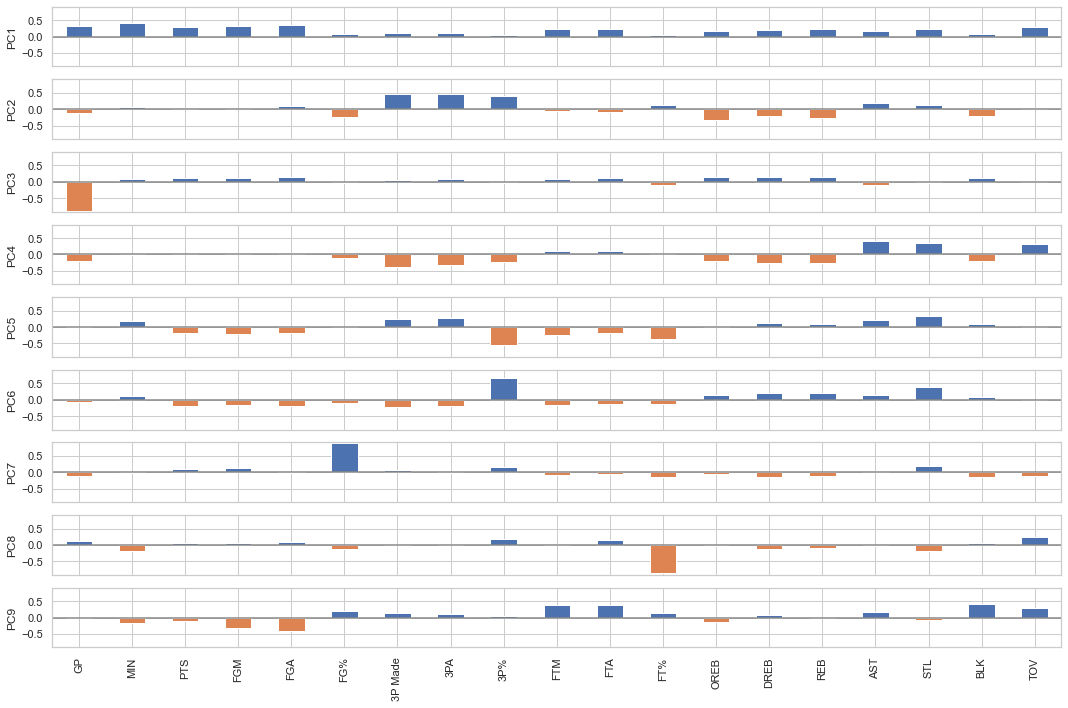

In [19]:
loadings = pd.DataFrame(pca.components_, columns=feature_names)
max_loading = 1.01 * loadings.abs().to_numpy().max()

fig, axes = plt.subplots(n_components, 1, figsize=(15, 10), sharex=True)
for i, ax in enumerate(axes):
    pc_loadings = loadings.iloc[i]  # get the loadings for the i-th PC
    colors = ["C0" if value > 0 else "C1" for value in pc_loadings]  # color the bars based on the sign of the loadings
    ax.axhline(color="#888888")  # draw a line at y = 0
    pc_loadings.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'PC{i+1}')
    ax.set_ylim(-max_loading, max_loading)
plt.tight_layout()  # adjust the layout
plt.show()

### 3.3 Feature importance with classifiers
We will look for the most important features according to three tree-based models fitted on the whole dataset.

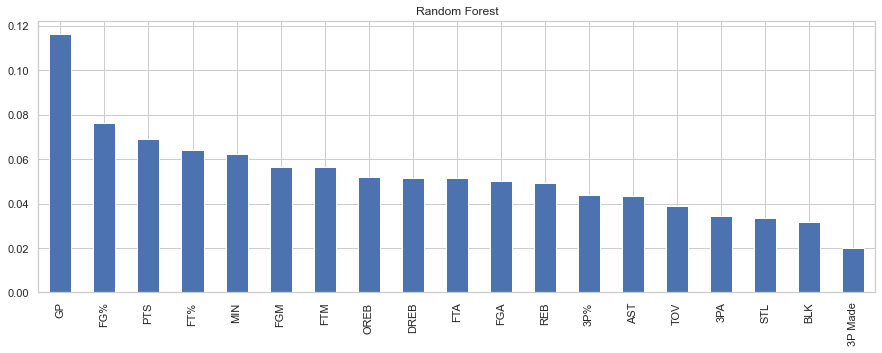

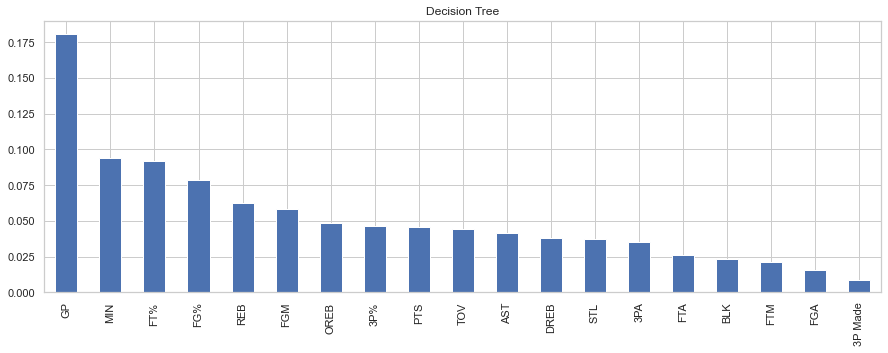

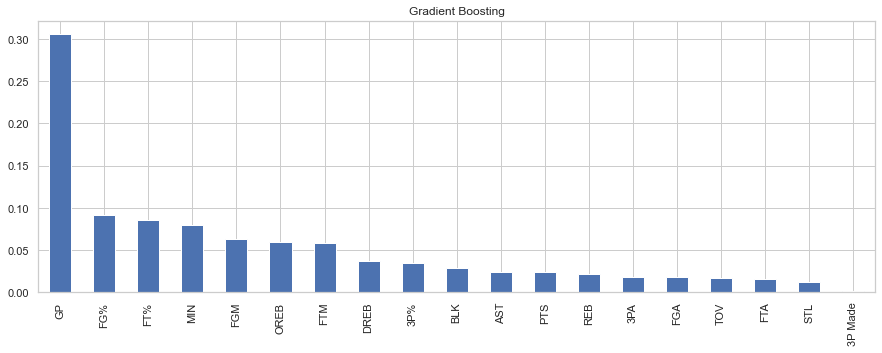

In [20]:
importance_models = {
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

for name, estimator in importance_models.items():
    estimator.fit(X_expl, labels)
    importances = pd.Series(estimator.feature_importances_, index=feature_names)
    importances.sort_values(ascending=False).plot(
        kind='bar', figsize=(15, 5), title=name
    )
    plt.show()

**Observations:** As concluded earlier, the number of games played is the most important factor, followed by the minutes played, the field goal percentage and the free throw percentage.

## 4. Model comparison

In [21]:
def plot_confusion_matrix(matrix, title):
    """Display a confusion matrix."""
    plt.figure()
    ax = sns.heatmap(matrix, annot=True, linewidths=1, cmap="Blues", fmt=".0f")
    ax.yaxis.set_ticklabels(ax.yaxis.get_ticklabels(), rotation=0, ha="right")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.title(title)
    plt.show()

def build_pipeline(classifier, use_pca=False):
    steps = [
        ("impute", SimpleImputer(strategy="constant", fill_value=0)),
        ("scale", MinMaxScaler())
    ]
    if use_pca:
        steps.append(("pca", PCA(n_components=0.95)))
    steps.append(("clf", classifier))
    return Pipeline(steps)

def score_classifier(features, estimator, labels, n_splits=5, name="", plot=False):
    """Cross-validate an estimator and summarise its perfomance."""
    features = np.asarray(features)
    labels = np.asarray(labels)
    splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

    confusion_total = np.zeros((2, 2))
    recalls, precisions, train_accuracies, test_accuracies = [], [], [], []

    for train_ids, test_ids in splitter.split(features, labels):
        model = clone(estimator)
        model.fit(features[train_ids], labels[train_ids])
        train_pred = model.predict(features[train_ids])
        test_pred = model.predict(features[test_ids])

        confusion_total += confusion_matrix(labels[test_ids], test_pred)
        recalls.append(recall_score(labels[test_ids], test_pred))
        precisions.append(precision_score(labels[test_ids], test_pred))
        train_accuracies.append(accuracy_score(labels[train_ids], train_pred))
        test_accuracies.append(accuracy_score(labels[test_ids], test_pred))

    if plot:
        plot_confusion_matrix(confusion_total, f"Confusion matrix: {name}")

    return {
        "recall": np.mean(recalls),
        "precision": np.mean(precisions),
        "train_accuracy": np.mean(train_accuracies),
        "test_accuracy": np.mean(test_accuracies)
    }

In [22]:
candidates = {
    "SVC": SVC(),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}
decorrelated_columns = X_decorrelated.columns.to_list()

rows = []
for model_name, classifier in candidates.items():
    variants = {
        "all features": (X_raw, build_pipeline(classifier)),
        "PCA": (X_raw, build_pipeline(classifier, use_pca=True)),
        "decorrelated": (X_raw[decorrelated_columns], build_pipeline(classifier))
    }
    for variant, (features, pipeline) in variants.items():
        scores = score_classifier(features, pipeline, labels)
        rows.append({"model": model_name, "features": variant, **scores})

comparison = pd.DataFrame(rows).round(3)
comparison.sort_values("recall", ascending=False)

,model,features,recall,precision,train_accuracy,test_accuracy
0,SVC,all features,0.828,0.735,0.725,0.708
2,SVC,decorrelated,0.828,0.712,0.693,0.686
1,SVC,PCA,0.821,0.734,0.730,0.704
9,Gradient Boosting,all features,0.801,0.733,0.862,0.696
10,Gradient Boosting,PCA,0.794,0.730,0.848,0.690
11,Gradient Boosting,decorrelated,0.792,0.702,0.774,0.662
3,Random Forest,all features,0.783,0.732,0.988,0.688
4,Random Forest,PCA,0.769,0.712,0.988,0.663
5,Random Forest,decorrelated,0.726,0.709,0.981,0.645
6,Decision Tree,all features,0.671,0.691,0.988,0.610


- **SVC on all features** has the best recall (0.83) with the best precision (0.74), and almost no gap between training and held-out accuracy (0.73 vs 0.71).
- Gradient Boosting is close on recall (0.80) but overfits clearly (0.86 vs 0.70), and Random Forest and Decision Tree overfit even more (training accuracy near 0.99).
- **PCA** brings no improvement, and the **decorrelated subset** is slightly worse, so all features are kept.

The recall difference between SVC and Gradient Boosting is small and within the noise of cross-validation. SVC on all features is retained because it matches or beats the other models while generalising best.

## 5. Tuning the model

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, labels, random_state=RANDOM_STATE, stratify=labels
)
base_rate = y_train.mean()
MIN_PRECISION = base_rate + 0.05  # precision must beat "predict yes for everyone"


def select_best(cv_results):
    """Return the index of the best-recall configuration with acceptable precisions."""
    recall = np.asarray(cv_results["mean_test_recall"])
    precision = np.asarray(cv_results["mean_test_precision"])
    eligible = precision >= MIN_PRECISION
    if not eligible.any():
        raise ValueError("No configuration beats the base-rate prediction.")
    return int(np.argmax(np.where(eligible, recall, -np.inf)))


pipeline = build_pipeline(SVC(kernel="rbf"))
param_grid = {  # hyperparameters to test
    "clf__C": [1, 10, 100],
    "clf__gamma": ["scale", 0.01, 0.1],
    "clf__class_weight": [None, "balanced"]
}

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring={"recall": "recall", "precision": "precision", "accuracy": "accuracy"},
    refit=select_best,
    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE),
    n_jobs=-1  # use all the cores
)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)

Best parameters: {'clf__C': 10, 'clf__class_weight': None, 'clf__gamma': 0.1}


In [29]:
cv_columns = [
    "param_clf__C",
    "param_clf__gamma",
    "param_clf__class_weight",
    "mean_test_recall",
    "mean_test_precision",
    "mean_test_accuracy"
]
pd.DataFrame(search.cv_results_)[cv_columns].round(3).sort_values(
    "mean_test_recall", ascending=False
).head(10)

,param_clf__C,param_clf__gamma,param_clf__class_weight,mean_test_recall,mean_test_precision,mean_test_accuracy
1,1,0.01,None,1.000,0.620,0.620
8,10,0.1,None,0.831,0.731,0.705
14,100,0.1,None,0.829,0.721,0.695
13,100,0.01,None,0.819,0.733,0.702
0,1,scale,None,0.818,0.731,0.700
2,1,0.1,None,0.818,0.736,0.705
7,10,0.01,None,0.817,0.738,0.706
6,10,scale,None,0.803,0.733,0.696
12,100,scale,None,0.731,0.713,0.650
16,100,0.01,balanced,0.677,0.787,0.686


For investors, this table means that roughly 7 in 10 "yes" predictions pay off, and about 1 in 6 long-career players is missed. There's likely a ceiling because rookie-year statistics only partly predict career length.

### 5.1 Decision threshold

In [30]:
prob_model = clone(search.best_estimator_).set_params(clf__probability=True)
oof_proba = cross_val_predict(
    prob_model,
    X_train,
    y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    method="predict_proba"
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)

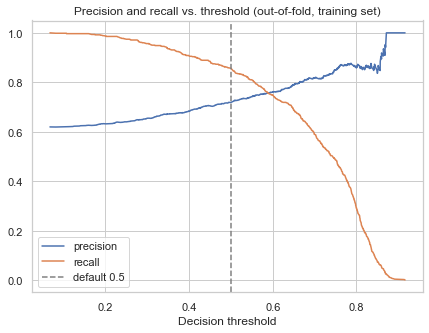

In [31]:
plt.figure(figsize=(7, 5))
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.axvline(0.5, color="grey", linestyle="--", label="default 0.5")
plt.xlabel("Decision threshold")
plt.title("Precision and recall vs. threshold (out-of-fold, training set)")
plt.legend()
plt.show()

              precision    recall  f1-score   support

         0.0       0.68      0.50      0.58       127
         1.0       0.74      0.86      0.79       208

    accuracy                           0.72       335
   macro avg       0.71      0.68      0.68       335
weighted avg       0.72      0.72      0.71       335



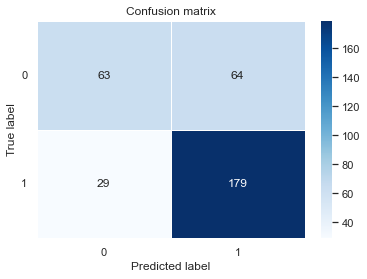

In [35]:
# Final estimate
threshold = 0.5
prob_model.fit(X_train, y_train)
test_proba = prob_model.predict_proba(X_test)[:, 1]
y_pred = (test_proba >= threshold).astype(int)
print(classification_report(y_test, y_pred))
plot_confusion_matrix(
    confusion_matrix(y_test, y_pred),
    "Confusion matrix"
)

## 6. Final model

In [ ]:
final_model = clone(search.best_estimator_).set_params(clf__probability=True)
final_model.fit(X_raw, labels)

with open("model.pkl", "wb") as f:
    pickle.dump(final_model, f)
with open("model_columns.pkl", "wb") as f:
    pickle.dump(feature_names, f)